# 1. Question

All figures are from synthetic data. Scenarios are hypothetical, and take rates are assumptions. Unit is the derived w30b journey, which misstates value slightly (recovered value is 2.9 percent below the hidden-intent truth).

In [1]:
import os
import pandas as pd
from IPython.display import Image, display

rep_dir = os.path.abspath(os.path.join(os.getcwd(), 'reports')) if os.path.exists('reports') else os.path.abspath(os.path.join(os.getcwd(), '..', 'reports'))
print('Reports directory:', rep_dir)

Reports directory: D:\Analyst\PaymentIQ\reports


# 2. Failed, recovered and unrecovered value

Total attempted value is 3,688 lakh (about 36.9 crore), with 419.9 lakh in failed first attempts and 402.5 lakh in recovery-eligible failed journeys. Of eligible value, 105.0 lakh recovered and 297.5 lakh remained unrecovered (95 percent bootstrap interval 285 to 310 lakh). Recovery by value is 26.1 percent against 32.4 percent by count because the largest payments fail most often on limits.

,pool,journeys,unrecovered_journeys,unrecovered_lakh,ci_low,ci_high
0,addr,23692,15812,209.79,202.20,217.69
1,limit,400,386,81.08,71.17,91.19
2,other,518,437,6.64,4.82,9.50
3,total,24610,16635,297.51,284.96,310.37


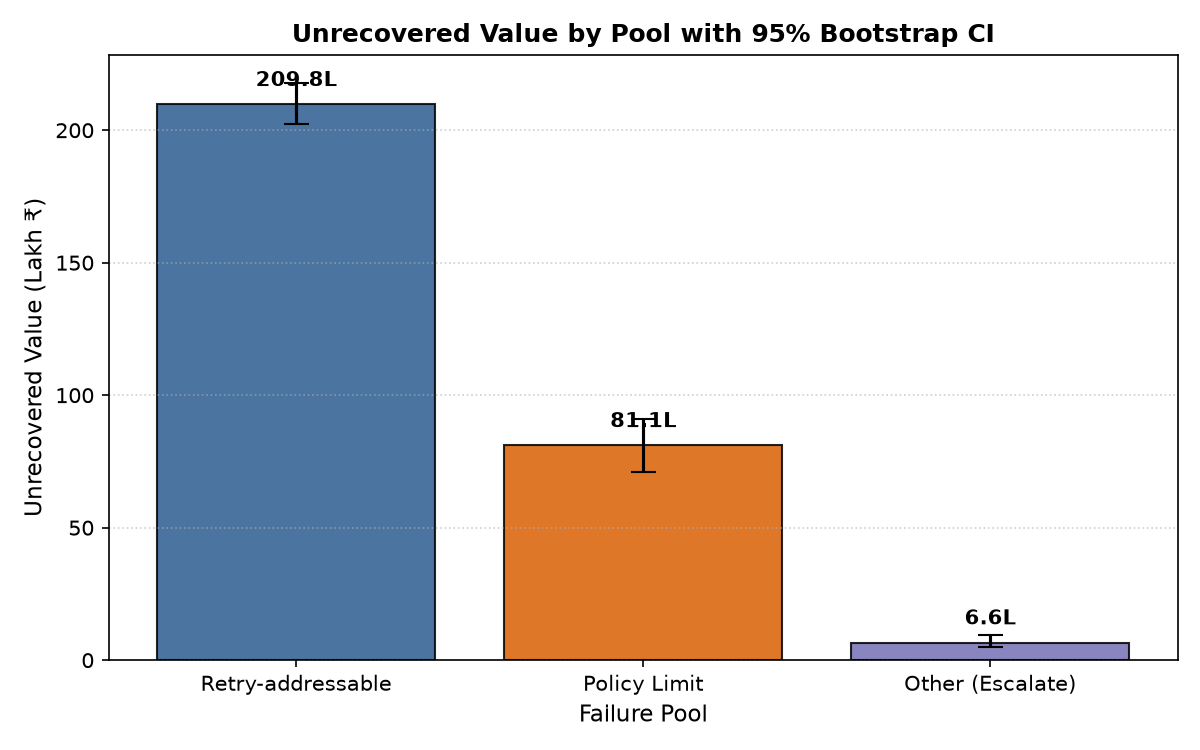

In [2]:
pools_df = pd.read_csv(os.path.join(rep_dir, 'phase6_pools.csv'))
display(pools_df)
display(Image(filename=os.path.join(rep_dir, 'figures', 'p6_unrecovered_by_pool.png')))

# 3. Where the value sits

LIM_02 (per-transaction limit at Small banks) holds 71.8 lakh unrecovered from 372 journeys, and together with LIM_03 limits account for 81.1 lakh (27 percent of unrecovered value). Timeouts (NET_01, NET_02, NET_03) hold 98.4 lakh across 10,400 journeys, while insufficient funds (BNK_03) holds 17.6 lakh. Consequently, Small banks recover only 12.4 percent of value versus 31.0 percent at Large banks.

In [3]:
print('Unrecovered value sits primarily in policy limits (81.1 lakh) and timeouts (98.4 lakh).')

Unrecovered value sits primarily in policy limits (81.1 lakh) and timeouts (98.4 lakh).


# 4. Scenarios (hypothetical)

Hypothetical gains on the retry-addressable pool range from 6.3 lakh (+2 pp) to 31.4 lakh (+10 pp), while alternative payment rails for policy limits could unlock 8.1 lakh (10% capture) to 20.3 lakh (25% capture). 400 limit journeys hold as much recoverable value as a 5 point retry gain across 23,692 journeys. Bootstrap intervals reflect sampling noise only, not whether gains are achievable.

,scenario,family,assumption,gain_lakh,ci_low,ci_high
0,+2 pp recovery (retry-addressable),Retry-addressable,+2 pp recovery gain on addressable pool,6.29,6.07,6.51
1,+5 pp recovery (retry-addressable),Retry-addressable,+5 pp recovery gain on addressable pool,15.72,15.18,16.29
2,+10 pp recovery (retry-addressable),Retry-addressable,+10 pp recovery gain on addressable pool,31.43,30.36,32.57
3,10% limit recovery (alternative rail),Limit,10% of limit unrecovered value captured,8.11,7.12,9.12
4,25% limit recovery (alternative rail),Limit,25% of limit unrecovered value captured,20.27,17.79,22.80


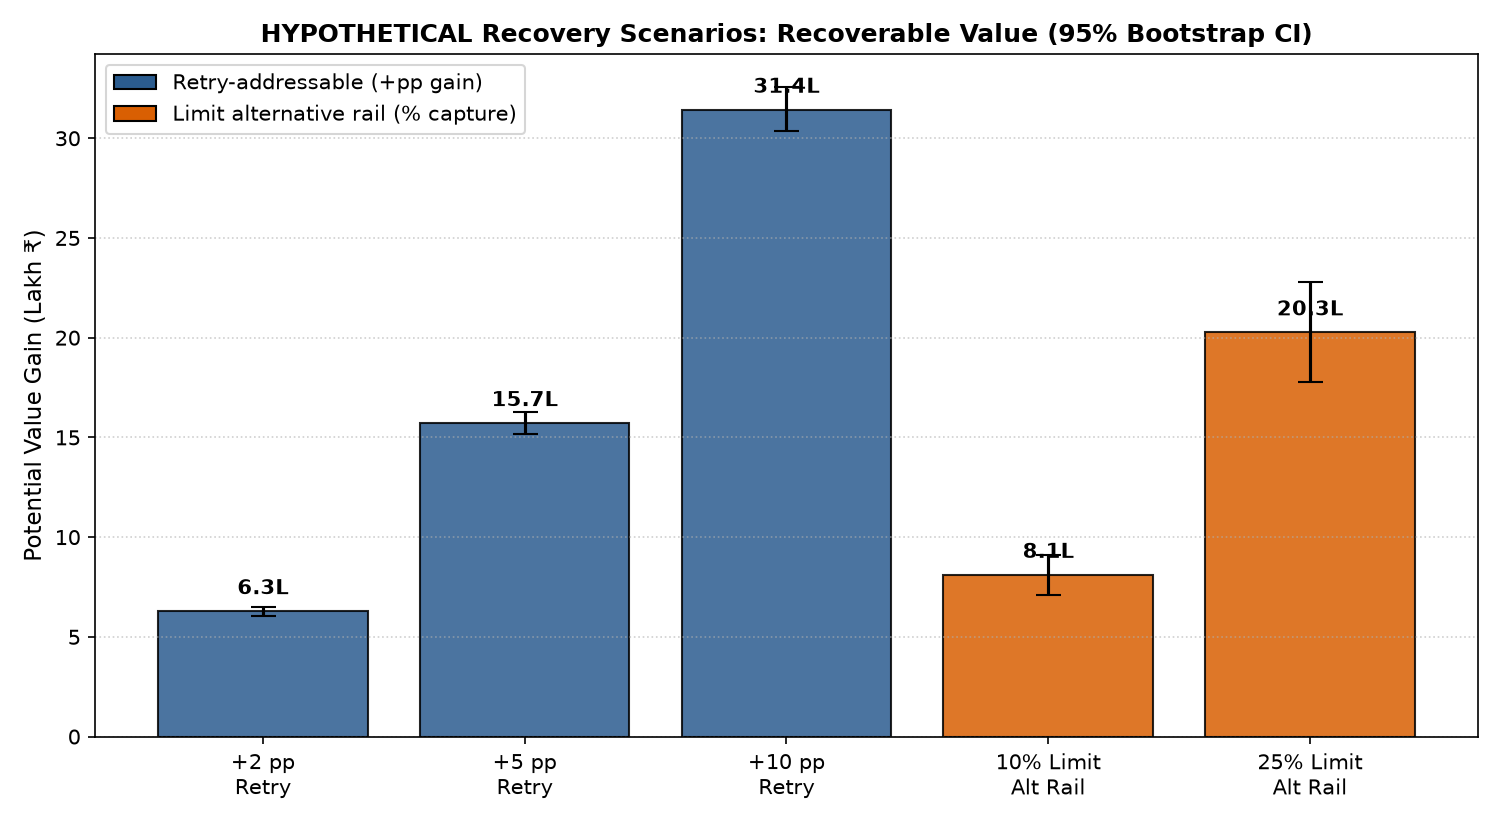

In [4]:
scenarios_df = pd.read_csv(os.path.join(rep_dir, 'phase6_scenarios.csv'))
display(scenarios_df[['scenario', 'family', 'assumption', 'gain_lakh', 'ci_low', 'ci_high']])
display(Image(filename=os.path.join(rep_dir, 'figures', 'p6_scenarios.png')))

# 5. Revenue versus value

Transaction value is not revenue; a PSP earns a fee, not the payment amount. At the base 0.5 percent take rate, even a +10 point recovery gain yields only about 15,700 rupees over six months. The business case must be justified on customer experience, retention, and reliability grounds rather than direct fee revenue.

In [5]:
display(scenarios_df[['scenario', 'gain_lakh', 'revenue_rs_at_0.3pct', 'revenue_rs_at_0.5pct', 'revenue_rs_at_1.0pct']])

,scenario,gain_lakh,revenue_rs_at_0.3pct,revenue_rs_at_0.5pct,revenue_rs_at_1.0pct
0,+2 pp recovery (retry-addressable),6.29,1886.1,3143.5,6286.9
1,+5 pp recovery (retry-addressable),15.72,4715.2,7858.7,15717.3
2,+10 pp recovery (retry-addressable),31.43,9430.4,15717.3,31434.7
3,10% limit recovery (alternative rail),8.11,2432.3,4053.8,8107.6
4,25% limit recovery (alternative rail),20.27,6080.7,10134.6,20269.1


# 6. Limits

All scenario gains assume extra recoveries look like the average unrecovered journey. Derived journeys misclassify some attempts (346 merged, about 676 split), and late-September journeys suffer from censoring. Sizing reflects hypothetical potential that must be validated through controlled experiments.

In [6]:
print('Phase 6 financial models complete: scenario outputs and bootstrap confidence intervals verified.')

Phase 6 financial models complete: scenario outputs and bootstrap confidence intervals verified.
